# PanAfriPay : analyse exploratoire des données (EDA)

**Objectif** : mesurer, sur les 5 fichiers CSV bruts, chaque anomalie annoncée dans le sujet et comparer avec le chiffre attendu.

**Règle** : ce notebook est en **lecture seule**. Rien n'est corrigé ni supprimé ici : les corrections se feront en silver.

**Plan**
1. Chargement et structure
2. Doublons
3. Montants et limites opérateur
4. Formats MSISDN
5. Intégrité référentielle et valeurs manquantes par conception
6. Dates de naissance
7. Coordonnées des agents
8. Transactions miroir
9. Vélocité
10. Cohérence des transactions
11. Fichiers `fx_rates` et `operators`
12. Synthèse, graphiques et conclusion

## 1. Chargement et structure

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Dossier des CSV : variable d'environnement DATA_DIR, sinon le dossier du notebook.
DATA_DIR = Path(os.getenv("DATA_DIR", "."))

# Les MSISDN sont lus en texte : sinon pandas peut les convertir en nombres et perdre le "+".
df_agents = pd.read_csv(DATA_DIR / "agents.csv")
df_customers = pd.read_csv(DATA_DIR / "customers.csv", dtype={"msisdn": "string"})
df_fx = pd.read_csv(DATA_DIR / "fx_rates.csv")
df_operators = pd.read_csv(DATA_DIR / "operators.csv")
df_transactions = pd.read_csv(
    DATA_DIR / "transactions.csv",
    dtype={"sender_msisdn": "string", "receiver_msisdn": "string"},
)

datasets = {
    "transactions": df_transactions,
    "agents": df_agents,
    "customers": df_customers,
    "operators": df_operators,
    "fx_rates": df_fx,
}

# Liste commune : chaque mesure ajoute une ligne, le tableau final de synthèse en est tiré.
resultats = []


def ajouter(anomalie, fichier, regle, compte, total, attendu_pct=None, attendu_txt=""):
    """Enregistre une mesure pour la synthèse finale."""
    compte = int(compte)
    pct = round(100 * compte / total, 2) if total else np.nan
    resultats.append({
        "anomalie": anomalie,
        "fichier": fichier,
        "regle": regle,
        "compte": compte,
        "pct": pct,
        "attendu": attendu_txt or (f"~{attendu_pct} %" if attendu_pct is not None else ""),
        "ecart_pts": round(pct - attendu_pct, 2) if attendu_pct is not None else np.nan,
    })


for nom, df in datasets.items():
    print(f"{nom:<13} {df.shape[0]:>7} lignes x {df.shape[1]:>2} colonnes")

transactions   109325 lignes x 18 colonnes
agents           5005 lignes x 12 colonnes
customers       50050 lignes x 11 colonnes
operators           5 lignes x  7 colonnes
fx_rates          270 lignes x  5 colonnes


In [2]:
for nom, df in datasets.items():
    print(f"\n--- {nom} : colonnes et valeurs manquantes ---")
    print(pd.DataFrame({
        "manquantes": df.isna().sum(),
        "pct": (df.isna().mean() * 100).round(2),
        "type": df.dtypes.astype(str),
    }))


--- transactions : colonnes et valeurs manquantes ---
                     manquantes    pct     type
transaction_id                0   0.00      str
transaction_ref               0   0.00      str
transaction_type              0   0.00      str
sender_msisdn                 0   0.00   string
receiver_msisdn           76403  69.89   string
agent_id                  57387  52.49      str
amount                        0   0.00  float64
currency                      0   0.00      str
fees                          0   0.00  float64
operator_code                 0   0.00      str
country_code                  0   0.00      str
transaction_status            0   0.00      str
initiated_at                  0   0.00      str
completed_at              12998  11.89      str
channel                       0   0.00      str
device_imei_hash          27779  25.41      str
error_code                96327  88.11      str
partner_merchant_id       89638  81.99      str

--- agents : colonnes et valeurs

## 2. Doublons techniques

Deux mesures différentes :
- **copies en trop** : lignes qui répètent un identifiant déjà vu (c'est le chiffre à comparer avec les « 5 % » du sujet) ;
- **lignes concernées** : toutes les lignes d'un groupe répété, originaux compris.

On sépare aussi les doublons **exacts** (toutes les colonnes identiques) des doublons **conflictuels** (même identifiant, valeurs différentes). Les conflictuels demandent une règle de résolution en silver.

In [3]:
controles_doublons = [
    ("transactions", df_transactions, "transaction_id", 5.0, "environ 5 %"),
    ("customers", df_customers, "customer_id", None, "50 doublons"),
    ("agents", df_agents, "agent_id", None, "5 doublons"),
]

lignes = []
for nom, df, cle, attendu_pct, attendu_txt in controles_doublons:
    serie = df[cle]
    copies = int((serie.notna() & serie.duplicated()).sum())
    groupe = serie.notna() & serie.duplicated(keep=False)
    exacts = int(df.duplicated().sum())
    lignes.append({
        "fichier": nom,
        "lignes": len(df),
        "copies_en_trop": copies,
        "pct_copies": round(100 * copies / len(df), 2),
        "lignes_concernees": int(groupe.sum()),
        "ids_repetes": int(serie[groupe].nunique()),
        "copies_exactes": exacts,
        "copies_conflictuelles": copies - exacts,
    })
    ajouter(f"Doublons {cle}", nom, f"{cle} répété (copies en trop)",
            copies, len(df), attendu_pct, attendu_txt)

display(pd.DataFrame(lignes))

# Exemple de doublon par fichier (3 premiers groupes)
for nom, df, cle, _, _ in controles_doublons:
    groupe = df[cle].notna() & df[cle].duplicated(keep=False)
    print(f"\n{nom} : exemples")
    display(df.loc[groupe].sort_values(cle).head(6))

,fichier,lignes,copies_en_trop,pct_copies,lignes_concernees,ids_repetes,copies_exactes,copies_conflictuelles
0,transactions,109325,5000,4.57,9860,4860,5000,0
1,customers,50050,50,0.10,99,49,50,0
2,agents,5005,5,0.10,10,5,5,0



transactions : exemples


,transaction_id,transaction_ref,transaction_type,sender_msisdn,receiver_msisdn,agent_id,amount,currency,fees,operator_code,country_code,transaction_status,initiated_at,completed_at,channel,device_imei_hash,error_code,partner_merchant_id
26729,0005d037-70f8-40c0-a960-1dd845f468b4,TRX-20260208-00004677,TRANSFER,+221738648715,+225770151203,NaN,10760.61,XOF,92.43,FREE,SEN,SUCCESS,2026-02-08 10:13:35+00:00,2026-02-08 10:14:06+00:00,APP,3267c20dd4eb1b51,NaN,NaN
103122,0005d037-70f8-40c0-a960-1dd845f468b4,TRX-20260208-00004677,TRANSFER,+221738648715,+225770151203,NaN,10760.61,XOF,92.43,FREE,SEN,SUCCESS,2026-02-08 10:13:35+00:00,2026-02-08 10:14:06+00:00,APP,3267c20dd4eb1b51,NaN,NaN
8712,000686e4-3d85-4ca3-985e-41e8f91daf1b,TRX-20260324-00045602,DEPOSIT,+221751902258,<NA>,AGT-00104700,145252.93,XOF,2287.50,FREE,SEN,SUCCESS,2026-03-24 20:34:48+00:00,2026-03-24 20:35:29+00:00,USSD,c49f3ef376853444,NaN,NaN
43687,000686e4-3d85-4ca3-985e-41e8f91daf1b,TRX-20260324-00045602,DEPOSIT,+221751902258,<NA>,AGT-00104700,145252.93,XOF,2287.50,FREE,SEN,SUCCESS,2026-03-24 20:34:48+00:00,2026-03-24 20:35:29+00:00,USSD,c49f3ef376853444,NaN,NaN
48149,00192b76-58a1-47cb-b298-fca31b741308,TRX-20260301-00075272,TRANSFER,+223641492806,+221602915684,NaN,93866.08,XOF,1361.15,MTN_MOMO,MLI,SUCCESS,2026-03-01 09:20:43+00:00,2026-03-01 09:21:25+00:00,USSD,NaN,NaN,NaN
49787,00192b76-58a1-47cb-b298-fca31b741308,TRX-20260301-00075272,TRANSFER,+223641492806,+221602915684,NaN,93866.08,XOF,1361.15,MTN_MOMO,MLI,SUCCESS,2026-03-01 09:20:43+00:00,2026-03-01 09:21:25+00:00,USSD,NaN,NaN,NaN



customers : exemples


,customer_id,msisdn,first_name,last_name,birth_date,kyc_level,registration_date,country_code,region,customer_status,account_balance
1,CUST-001000001,+224683565939,Salif,Faye,1984-03-01,LEVEL_2,2021-11-29,GIN,Kankan,DORMANT,103517.01
50022,CUST-001000001,+224683565939,Salif,Faye,1984-03-01,LEVEL_2,2021-11-29,GIN,Kankan,DORMANT,103517.01
43,CUST-001000043,+221700803485,Mohamed,Sané,2006-07-17,LEVEL_1,2025-01-05,SEN,Kédougou,ACTIVE,168316.25
50009,CUST-001000043,+221700803485,Mohamed,Sané,2006-07-17,LEVEL_1,2025-01-05,SEN,Kédougou,ACTIVE,168316.25
73,CUST-001000073,+221711311207,Mariama,Tall,1973-06-02,LEVEL_2,2023-08-08,SEN,Diourbel,ACTIVE,343462.94
50036,CUST-001000073,+221711311207,Mariama,Tall,1973-06-02,LEVEL_2,2023-08-08,SEN,Diourbel,ACTIVE,343462.94



agents : exemples


,agent_id,agent_name,agent_type,operator_code,country_code,region,city,latitude,longitude,onboarding_date,agent_status,commission_tier
33,AGT-00100033,Mini-marché Patte d'Oie,SUB_AGENT,WAVE,GIN,Boké,Boké,12.218093,-7.914921,2020-01-26,ACTIVE,T1
5004,AGT-00100033,Mini-marché Patte d'Oie,SUB_AGENT,WAVE,GIN,Boké,Boké,12.218093,-7.914921,2020-01-26,ACTIVE,T1
53,AGT-00100053,Cash Point Hann,MERCHANT,WAVE,SEN,Matam,Matam,15.920170,-14.606400,2022-03-23,ACTIVE,T1
5000,AGT-00100053,Cash Point Hann,MERCHANT,WAVE,SEN,Matam,Matam,15.920170,-14.606400,2022-03-23,ACTIVE,T1
78,AGT-00100078,Marché Sicap,MERCHANT,WAVE,SEN,Dakar,Dakar,16.528403,-14.207811,2019-10-28,ACTIVE,T2
5001,AGT-00100078,Marché Sicap,MERCHANT,WAVE,SEN,Dakar,Dakar,16.528403,-14.207811,2019-10-28,ACTIVE,T2


## 3. Montants et limites opérateur

`operators.csv` ne donne **pas de plafond par transaction**, seulement `transaction_limit_daily` et `transaction_limit_monthly`. Choix retenu : comparer chaque montant à la **limite journalière** de son opérateur. C'est une hypothèse de travail, à écrire dans le rapport.

À vérifier : l'**unité** des limites (devise) et le nombre de lignes sans limite correspondante.

In [4]:
print("Opérateurs :")
display(df_operators)
print("Devises par pays dans les transactions :")
display(df_transactions.groupby(["country_code", "currency"]).size().rename("nb"))

Opérateurs :


,operator_code,operator_name,country_code,license_number,transaction_limit_daily,transaction_limit_monthly,service_start_date
0,OM,Orange Money,SEN,BCEAO-EME-2010-014,2000000.0,10000000.0,2010-04-15
1,WAVE,Wave Mobile Money,SEN,BCEAO-EME-2018-022,5000000.0,20000000.0,2018-09-01
2,MTN_MOMO,MTN Mobile Money,CIV,BCEAO-EME-2009-008,2000000.0,10000000.0,2009-08-10
3,FREE,Free Money,SEN,BCEAO-EME-2019-031,1500000.0,8000000.0,2019-11-20
4,MOOV,Moov Money,MLI,BCEAO-EME-2012-005,1500000.0,8000000.0,2012-06-30


Devises par pays dans les transactions :


country_code  currency
CIV           XOF         22184
GIN           GNF         33019
MLI           XOF         10953
SEN           XOF         43169
Name: nb, dtype: int64

In [5]:
assert df_operators["operator_code"].is_unique, "operator_code doit être unique"

montants = pd.to_numeric(df_transactions["amount"], errors="coerce")
limite_jour = df_transactions["operator_code"].map(
    df_operators.set_index("operator_code")["transaction_limit_daily"]
)

masque_negatif = montants < 0
masque_nul = montants == 0
masque_manquant = montants.isna()
masque_sans_limite = limite_jour.isna()
masque_sup_limite = montants > limite_jour  # faux si la limite est absente
masque_invalide = masque_negatif | masque_sup_limite

n = len(df_transactions)
print(f"Montants manquants           : {int(masque_manquant.sum())}")
print(f"Montants nuls                : {int(masque_nul.sum())}")
print(f"Montants négatifs            : {int(masque_negatif.sum())} ({100 * masque_negatif.mean():.2f} %)")
print(f"Sans limite opérateur        : {int(masque_sans_limite.sum())}")
print(f"Montants > limite journalière: {int(masque_sup_limite.sum())} ({100 * masque_sup_limite.mean():.2f} %)")
print(f"Total négatifs + dépassements: {int(masque_invalide.sum())} ({100 * masque_invalide.mean():.2f} %)")
print(f"Chevauchement (négatif ET > limite) : {int((masque_negatif & masque_sup_limite).sum())}")

ajouter("Montants négatifs", "transactions", "amount < 0", masque_negatif.sum(), n, attendu_txt="inclus dans ~3 %")
ajouter("Montants > limite journalière", "transactions", "amount > transaction_limit_daily",
        masque_sup_limite.sum(), n, attendu_txt="inclus dans ~3 %")
ajouter("Montants invalides (total)", "transactions", "négatif OU > limite journalière",
        masque_invalide.sum(), n, 3.0)

print("\nDépassements par devise :")
display(
    df_transactions.assign(depasse=masque_sup_limite)
    .groupby("currency")["depasse"].agg(depassements="sum", transactions="size")
)
print("Exemples de dépassements :")
display(df_transactions.loc[masque_sup_limite, ["transaction_id", "operator_code", "currency", "amount"]]
        .assign(limite_jour=limite_jour[masque_sup_limite]).head(5))

Montants manquants           : 0
Montants nuls                : 0
Montants négatifs            : 1508 (1.38 %)
Sans limite opérateur        : 0
Montants > limite journalière: 1492 (1.36 %)
Total négatifs + dépassements: 3000 (2.74 %)
Chevauchement (négatif ET > limite) : 0

Dépassements par devise :


,depassements,transactions
currency,,
GNF,430,33019
XOF,1062,76306


Exemples de dépassements :


,transaction_id,operator_code,currency,amount,limite_jour
37,45942d36-9f01-4ff5-8404-e6a789a7c8f6,OM,XOF,13274335.22,2000000.0
87,9abf205a-8fb4-49aa-9101-df23c3aa2b80,MTN_MOMO,XOF,12321173.69,2000000.0
135,7fd36393-77f1-4c73-ac58-31d257806829,FREE,XOF,13887736.77,1500000.0
147,2ae7abc7-5c4b-4476-af6b-58ab384c22a1,MOOV,XOF,11500866.66,1500000.0
149,bd40d9a7-4487-4189-8d68-f957007ff395,OM,XOF,13010017.86,2000000.0


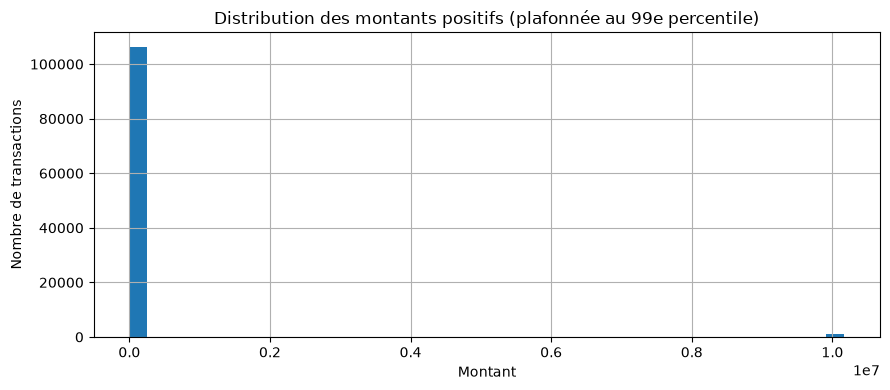

In [6]:
plt.figure(figsize=(9, 4))
positifs = montants[montants >= 0]
positifs.clip(upper=positifs.quantile(0.99)).hist(bins=40)
plt.title("Distribution des montants positifs (plafonnée au 99e percentile)")
plt.xlabel("Montant")
plt.ylabel("Nombre de transactions")
plt.tight_layout()
plt.show()

## 4. Formats MSISDN

Le format correct est `+` suivi de 8 à 15 chiffres. On mesure sur les valeurs **brutes** (espaces au début ou à la fin compris), puis on teste si une normalisation simple (suppression des espaces, `00` remplacé par `+`, `+` ajouté devant un numéro composé uniquement de chiffres) suffit à les réparer.

Un numéro peut cumuler plusieurs défauts : les catégories ne s'additionnent pas, on compte donc le total « non conforme » directement.

In [7]:
FORMAT_CANONIQUE = r"\+[1-9]\d{7,14}"


def normaliser_msisdn(serie):
    """Forme canonique exploratoire : sans espaces, 00 -> +, + ajouté si absent."""
    s = serie.astype("string").str.strip()
    s = s.str.replace(r"\s+", "", regex=True)
    s = s.str.replace(r"^00", "+", regex=True)
    chiffres_seuls = s.str.fullmatch(r"[1-9]\d{10,14}", na=False)
    return s.where(~chiffres_seuls, "+" + s)


def diagnostic_msisdn(serie, fichier, colonne, attendu_pct=None):
    brut = serie.astype("string")
    non_vide = brut.notna() & brut.str.strip().ne("")
    conforme = brut.str.fullmatch(FORMAT_CANONIQUE, na=False)
    non_conforme = non_vide & ~conforme
    repare = normaliser_msisdn(brut).str.fullmatch(FORMAT_CANONIQUE, na=False)
    irreparable = non_conforme & ~repare

    avec_espaces = non_vide & brut.str.contains(r"\s", na=False)
    prefixe_00 = non_vide & brut.str.strip().str.startswith("00", na=False)
    chiffres_seuls = non_vide & brut.str.strip().str.fullmatch(r"\d+", na=False) & ~prefixe_00

    print(f"\n--- {fichier}.{colonne} ---")
    print(f"Valeurs vides                         : {int((~non_vide).sum())}")
    print(f"Avec espaces                          : {int(avec_espaces.sum())}")
    print(f"Commençant par 00                     : {int(prefixe_00.sum())}")
    print(f"Chiffres seuls, ni '+' ni 00          : {int(chiffres_seuls.sum())}")
    print(f"NON CONFORMES (format brut)           : {int(non_conforme.sum())} "
          f"({100 * non_conforme.sum() / non_vide.sum():.2f} % des valeurs non vides)")
    print(f"Toujours invalides après normalisation: {int(irreparable.sum())}")
    ajouter("MSISDN non conforme", fichier, f"{colonne} ne respecte pas +<8 à 15 chiffres>",
            non_conforme.sum(), int(non_vide.sum()), attendu_pct)
    if irreparable.any():
        display(brut[irreparable].head(5))


diagnostic_msisdn(df_transactions["sender_msisdn"], "transactions", "sender_msisdn", 2.5)
diagnostic_msisdn(df_transactions["receiver_msisdn"], "transactions", "receiver_msisdn", 2.5)
diagnostic_msisdn(df_customers["msisdn"], "customers", "msisdn", 2.5)


--- transactions.sender_msisdn ---
Valeurs vides                         : 0
Avec espaces                          : 1017
Commençant par 00                     : 1061
Chiffres seuls, ni '+' ni 00          : 497
NON CONFORMES (format brut)           : 2575 (2.36 % des valeurs non vides)
Toujours invalides après normalisation: 0

--- transactions.receiver_msisdn ---
Valeurs vides                         : 76403
Avec espaces                          : 293
Commençant par 00                     : 293
Chiffres seuls, ni '+' ni 00          : 160
NON CONFORMES (format brut)           : 746 (2.27 % des valeurs non vides)
Toujours invalides après normalisation: 0

--- customers.msisdn ---
Valeurs vides                         : 0
Avec espaces                          : 491
Commençant par 00                     : 470
Chiffres seuls, ni '+' ni 00          : 241
NON CONFORMES (format brut)           : 1202 (2.40 % des valeurs non vides)
Toujours invalides après normalisation: 0


## 5. Intégrité référentielle et valeurs manquantes par conception

`agent_id` **vide** n'est pas une anomalie pour une opération sans agent (virement entre clients, par exemple). L'anomalie, c'est un `agent_id` **renseigné** mais **absent** de `agents.csv`.

Le tableau croisé par type de transaction montre quels vides sont normaux.

In [8]:
agents_connus = set(df_agents["agent_id"].dropna())
agent_renseigne = df_transactions["agent_id"].notna()
agent_orphelin = agent_renseigne & ~df_transactions["agent_id"].isin(agents_connus)

print(f"agent_id vide                : {int((~agent_renseigne).sum())}")
print(f"agent_id renseigné inexistant: {int(agent_orphelin.sum())} ({100 * agent_orphelin.mean():.2f} %)")
ajouter("agent_id inexistant", "transactions", "agent_id renseigné et absent de agents.csv",
        agent_orphelin.sum(), len(df_transactions), 1.0)

print("\nOrphelins par type de transaction :")
display(df_transactions.loc[agent_orphelin, "transaction_type"].value_counts())
print("Exemples :")
display(df_transactions.loc[agent_orphelin, ["transaction_id", "transaction_type", "agent_id", "amount"]].head(5))

agent_id vide                : 57387
agent_id renseigné inexistant: 1000 (0.91 %)

Orphelins par type de transaction :


transaction_type
DEPOSIT    1000
Name: count, dtype: int64

Exemples :


,transaction_id,transaction_type,agent_id,amount
310,0cfca24e-27d6-40f0-83e3-9675eeec775e,DEPOSIT,AGT-9900388875,64486.30
408,f78b8087-4770-445c-8b42-502b1e095aa0,DEPOSIT,AGT-9900782840,184431.27
419,d83f132d-6c43-4b30-b993-b7081092e7ae,DEPOSIT,AGT-9900550911,32009.82
565,95cf2b7a-271a-4b69-995f-68929a1918f2,DEPOSIT,AGT-9900292979,59308.39
636,dd086289-088c-45e8-9cf7-a860e8dd9f3c,DEPOSIT,AGT-9900895317,49735.51


In [9]:
for colonne in ["receiver_msisdn", "agent_id", "partner_merchant_id"]:
    print(f"\n{colonne} vide, par type de transaction (False = renseigné, True = vide) :")
    display(pd.crosstab(df_transactions["transaction_type"], df_transactions[colonne].isna()))


receiver_msisdn vide, par type de transaction (False = renseigné, True = vide) :


receiver_msisdn,False,True
transaction_type,,
AIRTIME_TOPUP,0,5265
BILL_PAYMENT,0,8557
DEPOSIT,289,27804
MERCHANT_PAYMENT,0,10932
TRANSFER,32633,0
WITHDRAWAL,0,23845



agent_id vide, par type de transaction (False = renseigné, True = vide) :


agent_id,False,True
transaction_type,,
AIRTIME_TOPUP,0,5265
BILL_PAYMENT,0,8557
DEPOSIT,28093,0
MERCHANT_PAYMENT,0,10932
TRANSFER,0,32633
WITHDRAWAL,23845,0



partner_merchant_id vide, par type de transaction (False = renseigné, True = vide) :


partner_merchant_id,False,True
transaction_type,,
AIRTIME_TOPUP,0,5265
BILL_PAYMENT,8557,0
DEPOSIT,198,27895
MERCHANT_PAYMENT,10932,0
TRANSFER,0,32633
WITHDRAWAL,0,23845


## 6. Dates de naissance

Trois filtres : les 4 valeurs sentinelles du sujet, les dates impossibles à convertir, et une règle de plausibilité (âge négatif ou supérieur à 110 ans). Les dates `1900`, `1850` et `9999` se convertissent en vraies dates : seule la règle d'âge les détecte.

In [10]:
SENTINELLES = {"1900-01-01", "9999-12-31", "0000-00-00", "1850-05-12"}
ANNEE_REFERENCE = pd.Timestamp.today().year

brut = df_customers["birth_date"].astype("string").str.strip()
dates = pd.to_datetime(brut, format="%Y-%m-%d", errors="coerce")
age = ANNEE_REFERENCE - dates.dt.year  # âge approximatif, suffisant pour détecter l'impossible

sentinelle = brut.isin(SENTINELLES)
non_convertible = dates.isna()
age_impossible = age.lt(0) | age.gt(110)
date_invalide = sentinelle | non_convertible | age_impossible
hors_sentinelles = date_invalide & ~sentinelle

print(f"Sentinelles du sujet            : {int(sentinelle.sum())} ({100 * sentinelle.mean():.2f} %)")
print(f"Non convertibles                : {int(non_convertible.sum())}")
print(f"Âge impossible (<0 ou >110 ans) : {int(age_impossible.sum())}")
print(f"Total invalides (union)         : {int(date_invalide.sum())} ({100 * date_invalide.mean():.2f} %)")
print(f"Invalides hors des 4 sentinelles: {int(hors_sentinelles.sum())}")
print(f"Mineurs (info, non invalides)   : {int((age.lt(18) & ~date_invalide).sum())}")

ajouter("Dates de naissance sentinelles", "customers", "4 valeurs sentinelles du sujet",
        sentinelle.sum(), len(df_customers), 0.5)
ajouter("Dates de naissance invalides (règle d'âge)", "customers", "sentinelle, non convertible ou âge <0 / >110",
        date_invalide.sum(), len(df_customers), 0.5)

if hors_sentinelles.any():
    display(df_customers.loc[hors_sentinelles, ["customer_id", "birth_date"]].head(5))

Sentinelles du sujet            : 245 (0.49 %)
Non convertibles                : 56
Âge impossible (<0 ou >110 ans) : 189
Total invalides (union)         : 245 (0.49 %)
Invalides hors des 4 sentinelles: 0
Mineurs (info, non invalides)   : 0


## 7. Coordonnées géographiques des agents

`between` renvoie `False` sur une valeur vide : il faut donc tester la présence **avant** de tester les limites, sinon les valeurs vides sont comptées comme « hors limites ».

In [11]:
lat = pd.to_numeric(df_agents["latitude"], errors="coerce")
lon = pd.to_numeric(df_agents["longitude"], errors="coerce")

geo_absente = lat.isna() | lon.isna()
geo_hors_limites = lat.notna() & lon.notna() & (~lat.between(-90, 90) | ~lon.between(-180, 180))
geo_zero = lat.notna() & lon.notna() & (lat == 0) & (lon == 0)

print(f"Agents sans coordonnées complètes: {int(geo_absente.sum())} ({100 * geo_absente.mean():.2f} %)")
print(f"Coordonnées hors limites         : {int(geo_hors_limites.sum())}")
print(f"Coordonnées (0, 0)               : {int(geo_zero.sum())}")

ajouter("Agents sans coordonnées", "agents", "latitude ou longitude vide",
        geo_absente.sum(), len(df_agents), attendu_txt="quelques cas")
ajouter("Coordonnées hors limites", "agents", "lat hors [-90, 90] ou lon hors [-180, 180]",
        geo_hors_limites.sum(), len(df_agents), attendu_txt="aucune annoncée")

display(df_agents.loc[geo_absente].head(5))

Agents sans coordonnées complètes: 160 (3.20 %)
Coordonnées hors limites         : 0
Coordonnées (0, 0)               : 0


,agent_id,agent_name,agent_type,operator_code,country_code,region,city,latitude,longitude,onboarding_date,agent_status,commission_tier
103,AGT-00100103,Mini-marché Guédiawaye,SUB_AGENT,OM,MLI,Koulikoro,Koulikoro,NaN,NaN,2024-08-16,ACTIVE,T1
199,AGT-00100199,Kiosque Wakhinane,SUB_AGENT,MOOV,GIN,Kindia,Kindia,NaN,NaN,2020-03-17,ACTIVE,T1
234,AGT-00100234,Kiosque Touba,SUB_AGENT,WAVE,SEN,Dakar,Dakar,NaN,NaN,2023-07-30,ACTIVE,T2
237,AGT-00100237,Kiosque Sicap,SUB_AGENT,OM,CIV,Yamoussoukro,Yamoussoukro,NaN,NaN,2020-10-06,ACTIVE,T1
263,AGT-00100263,Marché Tabaski,MERCHANT,OM,GIN,Conakry,Conakry,NaN,NaN,2020-08-02,ACTIVE,T1


## 8. Transactions miroir

Deux transactions A -> B et B -> A, pour le **même montant exact**, à moins de 60 secondes d'écart. On retire d'abord les copies de `transaction_id` pour ne pas fabriquer de fausses paires, et on teste avec les numéros bruts puis normalisés.

In [12]:
def trouver_paires_miroir(df, col_emetteur, col_recepteur, fenetre_s=60, normaliser=False):
    t = df[["transaction_id", col_emetteur, col_recepteur, "amount", "initiated_at"]].copy()
    t = t.drop_duplicates(subset="transaction_id")
    if normaliser:
        t[col_emetteur] = normaliser_msisdn(t[col_emetteur])
        t[col_recepteur] = normaliser_msisdn(t[col_recepteur])
    t = t.rename(columns={col_emetteur: "emetteur", col_recepteur: "recepteur"})
    t["initiated_at"] = pd.to_datetime(t["initiated_at"], errors="coerce", utc=True)
    t["amount"] = pd.to_numeric(t["amount"], errors="coerce")
    t = t.dropna()

    inverse = t.rename(columns={
        "transaction_id": "transaction_id_B",
        "emetteur": "recepteur",
        "recepteur": "emetteur",
        "initiated_at": "timestamp_B",
    })
    paires = t.merge(inverse, on=["emetteur", "recepteur", "amount"])
    ecart = (paires["initiated_at"] - paires["timestamp_B"]).abs()
    paires = paires[
        (ecart < pd.Timedelta(seconds=fenetre_s))
        & (paires["transaction_id"] < paires["transaction_id_B"])  # une seule fois par paire
    ].drop_duplicates(subset=["transaction_id", "transaction_id_B"])
    return paires.assign(ecart_s=ecart.dt.total_seconds())


paires_brutes = trouver_paires_miroir(df_transactions, "sender_msisdn", "receiver_msisdn")
paires_norm = trouver_paires_miroir(df_transactions, "sender_msisdn", "receiver_msisdn", normaliser=True)

print(f"Paires miroir (numéros bruts)      : {len(paires_brutes)}")
print(f"Paires miroir (numéros normalisés) : {len(paires_norm)}")
ajouter("Transactions miroir", "transactions", "A->B et B->A, même montant, moins de 60 s (numéros normalisés)",
        len(paires_norm), len(df_transactions), attendu_txt="~150 paires")

display(paires_norm[["transaction_id", "transaction_id_B", "emetteur", "recepteur",
                     "amount", "initiated_at", "ecart_s"]].head(5))

Paires miroir (numéros bruts)      : 150
Paires miroir (numéros normalisés) : 150


,transaction_id,transaction_id_B,emetteur,recepteur,amount,initiated_at,ecart_s
1,dc3e213b-514a-4d89-9184-ba552d764433,f4f5334b-012a-404e-895a-ad33ff6e7918,+221729229138,+221786880787,104707.70,2026-02-08 17:00:29+00:00,29.0
2,01760cec-9b8c-41ad-8400-9dcf83545fbf,cfb45c06-f850-4aad-9a8c-299a5618cc7d,+225652165686,+221668377358,116592.88,2026-01-28 18:00:00+00:00,39.0
3,0749f612-cb21-4406-894c-c1cbe4f1d11b,7b5b71eb-fa92-4502-b350-779137aa7238,+221754407195,+224760121724,112410.00,2026-03-21 13:00:47+00:00,47.0
5,0471bf75-d4de-4f4f-9dbf-74df154551b3,80cc80de-1658-4c45-9634-489698971cc5,+221652403498,+225725585416,111348.00,2026-01-08 09:00:00+00:00,52.0
6,2b65dfdd-4103-420d-bed7-fa89fa008d5c,776dcf3d-1cd2-413d-b699-cb6392d22e1f,+225701355533,+221779125553,77944.65,2026-03-15 10:00:22+00:00,22.0


## 9. Vélocité

Pour chaque client (numéro **normalisé**), on calcule le plus grand nombre de transactions dans une fenêtre glissante de 10 minutes. Le seuil du sujet est de 25. Regarder aussi le maximum des **autres** clients permet de justifier ce seuil.

In [13]:
SEUIL_VELOCITE = 25
FENETRE_S = 10 * 60

tx_v = df_transactions[["sender_msisdn", "initiated_at"]].copy()
tx_v["client"] = normaliser_msisdn(tx_v["sender_msisdn"])
tx_v["t"] = pd.to_datetime(tx_v["initiated_at"], errors="coerce", utc=True)
tx_v = tx_v.dropna(subset=["client", "t"]).sort_values(["client", "t"])
tx_v["sec"] = ((tx_v["t"] - pd.Timestamp("1970-01-01", tz="UTC")) // pd.Timedelta(seconds=1)).astype("int64")


def max_dans_fenetre(secondes):
    t = secondes.to_numpy()
    debut = np.searchsorted(t, t - FENETRE_S, side="right")  # premier index dans la fenêtre
    return int((np.arange(len(t)) - debut + 1).max())


max_par_client = tx_v.groupby("client")["sec"].apply(max_dans_fenetre).sort_values(ascending=False)
suspects_velocite = max_par_client[max_par_client >= SEUIL_VELOCITE]

print(f"Clients avec au moins {SEUIL_VELOCITE} transactions en 10 min : {len(suspects_velocite)}")
print("Top 10 des maxima par client :")
display(max_par_client.head(10))
autres = max_par_client[max_par_client < SEUIL_VELOCITE]
print(f"Maximum parmi les autres clients : {autres.max() if len(autres) else 'n/a'}")

ajouter("Vélocité anormale", "transactions", f">= {SEUIL_VELOCITE} transactions en 10 min (même client)",
        len(suspects_velocite), tx_v["client"].nunique(), attendu_txt="1 cas")

Clients avec au moins 25 transactions en 10 min : 1
Top 10 des maxima par client :


client
+225771702289    25
+225697762774     4
+223609115161     4
+224722765276     4
+225725687422     4
+221627190488     4
+224626091330     4
+225729243049     4
+225638531941     4
+221792472059     4
Name: sec, dtype: int64

Maximum parmi les autres clients : 4


## 10. Cohérence des transactions

Contrôles qui ne figurent pas dans le sujet mais que le pipeline devra gérer : ordre des dates, frais négatifs, statut contre `completed_at`, et valeurs distinctes des colonnes catégorielles.

In [14]:
initie = pd.to_datetime(df_transactions["initiated_at"], errors="coerce", utc=True)
termine = pd.to_datetime(df_transactions["completed_at"], errors="coerce", utc=True)
frais = pd.to_numeric(df_transactions["fees"], errors="coerce")

fin_avant_debut = termine.notna() & initie.notna() & (termine < initie)
print(f"completed_at avant initiated_at : {int(fin_avant_debut.sum())}")
print(f"Frais négatifs                   : {int((frais < 0).sum())}")
print(f"initiated_at non convertible     : {int(initie.isna().sum())}")
print(f"Période couverte                 : {initie.min()}  ->  {initie.max()}")

print("\nStatut selon la présence de completed_at (True = vide) :")
display(pd.crosstab(df_transactions["transaction_status"], df_transactions["completed_at"].isna()))

for colonne in ["transaction_type", "transaction_status", "currency", "channel", "error_code"]:
    print(f"\n{colonne} :")
    display(df_transactions[colonne].value_counts(dropna=False))

completed_at avant initiated_at : 0
Frais négatifs                   : 0
initiated_at non convertible     : 0
Période couverte                 : 2026-01-01 06:00:14+00:00  ->  2026-03-31 22:59:50+00:00

Statut selon la présence de completed_at (True = vide) :


completed_at,False,True
transaction_status,,
FAILED,0,6531
PENDING,0,3248
REVERSED,0,2171
SUCCESS,96327,0
TIMEOUT,0,1048



transaction_type :


transaction_type
TRANSFER            32633
DEPOSIT             28093
WITHDRAWAL          23845
MERCHANT_PAYMENT    10932
BILL_PAYMENT         8557
AIRTIME_TOPUP        5265
Name: count, dtype: int64


transaction_status :


...

currency
XOF    76306
GNF    33019
Name: count, dtype: int64


channel :


channel
APP            43995
USSD           38225
AGENT          21651
API_PARTNER     5454
Name: count, dtype: int64


error_code :


error_code
NaN                     96327
E_INVALID_PIN            2230
E_TECH                   2221
E_TIMEOUT                2202
E_LIMIT_EXCEEDED         2169
E_DECLINED               2090
E_INSUFFICIENT_FUNDS     2086
Name: count, dtype: int64

## 11. Fichiers `fx_rates` et `operators`

Ces deux fichiers servent à convertir les montants et à fixer les plafonds : on vérifie les devises couvertes, la période des taux et l'absence de doublons.

In [15]:
print("Taux de change : paires disponibles")
display(df_fx.groupby(["from_currency", "to_currency"]).size().rename("nb_taux"))
print(f"Période : {df_fx['rate_date'].min()}  ->  {df_fx['rate_date'].max()}")

doublons_fx = df_fx.duplicated(subset=["rate_date", "from_currency", "to_currency"]).sum()
print(f"Doublons (date, paire)  : {int(doublons_fx)}")
print(f"Taux <= 0               : {int((pd.to_numeric(df_fx['exchange_rate'], errors='coerce') <= 0).sum())}")

devises_tx = set(df_transactions["currency"].dropna())
devises_fx = set(df_fx["from_currency"]) | set(df_fx["to_currency"])
print(f"Devises des transactions absentes de fx_rates : {sorted(devises_tx - devises_fx) or 'aucune'}")

jours_tx = pd.to_datetime(df_transactions["initiated_at"], errors="coerce", utc=True).dt.strftime("%Y-%m-%d").unique()
jours_fx = set(df_fx["rate_date"].astype("string"))
print(f"Jours de transactions sans taux de change : {len(set(jours_tx) - jours_fx)}")

Taux de change : paires disponibles


from_currency  to_currency
GNF            USD            90
XOF            GNF            90
               USD            90
Name: nb_taux, dtype: int64

Période : 2026-01-01  ->  2026-03-31
Doublons (date, paire)  : 0
Taux <= 0               : 0
Devises des transactions absentes de fx_rates : aucune
Jours de transactions sans taux de change : 0


## 12. Synthèse, graphiques et conclusion

Les catégories se chevauchent : ne les additionne pas pour obtenir un taux global d'anomalies. Les dénominateurs diffèrent selon la mesure (transactions, clients, agents, valeurs non vides).

In [16]:
synthese = pd.DataFrame(resultats)
display(synthese)

try:
    print(synthese.to_markdown(index=False))  # à coller dans docs/profiling.md
except ImportError:
    print("Installe tabulate (pip install tabulate) pour exporter le tableau en Markdown.")

,anomalie,fichier,regle,compte,pct,attendu,ecart_pts
0,Doublons transaction_id,transactions,transaction_id répété (copies en trop),5000,4.57,environ 5 %,-0.43
1,Doublons customer_id,customers,customer_id répété (copies en trop),50,0.10,50 doublons,NaN
2,Doublons agent_id,agents,agent_id répété (copies en trop),5,0.10,5 doublons,NaN
3,Montants négatifs,transactions,amount < 0,1508,1.38,inclus dans ~3 %,NaN
4,Montants > limite journalière,transactions,amount > transaction_limit_daily,1492,1.36,inclus dans ~3 %,NaN
5,Montants invalides (total),transactions,négatif OU > limite journalière,3000,2.74,~3.0 %,-0.26
6,MSISDN non conforme,transactions,sender_msisdn ne respecte pas +<8 à 15 chiffres>,2575,2.36,~2.5 %,-0.14
7,MSISDN non conforme,transactions,receiver_msisdn ne respecte pas +<8 à 15 chiff...,746,2.27,~2.5 %,-0.23
8,MSISDN non conforme,customers,msisdn ne respecte pas +<8 à 15 chiffres>,1202,2.40,~2.5 %,-0.10
9,agent_id inexistant,transactions,agent_id renseigné et absent de agents.csv,1000,0.91,~1.0 %,-0.09


| anomalie                                   | fichier      | regle                                                          |   compte |   pct | attendu          |   ecart_pts |
|:-------------------------------------------|:-------------|:---------------------------------------------------------------|---------:|------:|:-----------------|------------:|
| Doublons transaction_id                    | transactions | transaction_id répété (copies en trop)                         |     5000 |  4.57 | environ 5 %      |       -0.43 |
| Doublons customer_id                       | customers    | customer_id répété (copies en trop)                            |       50 |  0.1  | 50 doublons      |      nan    |
| Doublons agent_id                          | agents       | agent_id répété (copies en trop)                               |        5 |  0.1  | 5 doublons       |      nan    |
| Montants négatifs                          | transactions | amount < 0                                 

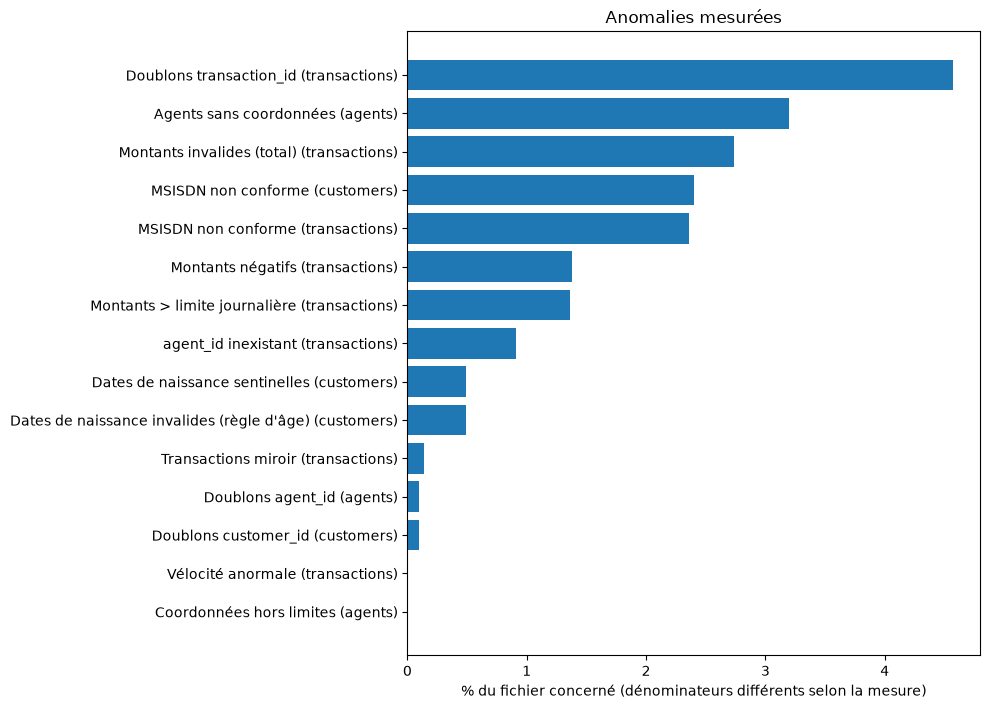

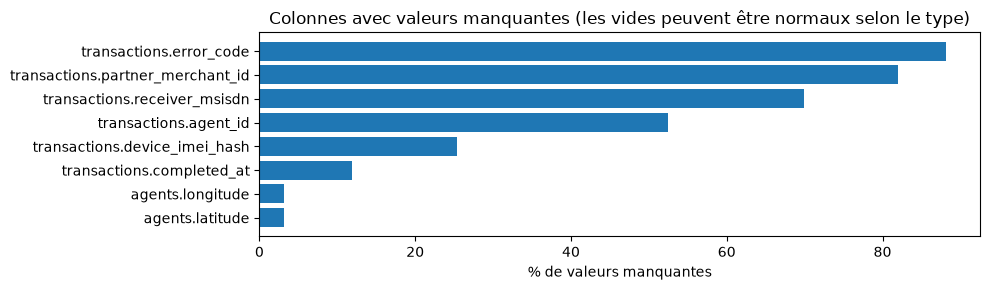

In [17]:
graphique = synthese.sort_values("pct")
plt.figure(figsize=(10, max(4, 0.45 * len(graphique))))
plt.barh(graphique["anomalie"] + " (" + graphique["fichier"] + ")", graphique["pct"])
plt.xlabel("% du fichier concerné (dénominateurs différents selon la mesure)")
plt.title("Anomalies mesurées")
plt.tight_layout()
plt.show()

manquants = pd.concat(
    {nom: df.isna().mean() * 100 for nom, df in datasets.items()}
).rename("pct")
manquants = manquants[manquants > 0].sort_values()
manquants.index = [f"{f}.{c}" for f, c in manquants.index]

plt.figure(figsize=(10, max(3, 0.35 * len(manquants))))
plt.barh(manquants.index, manquants.values)
plt.xlabel("% de valeurs manquantes")
plt.title("Colonnes avec valeurs manquantes (les vides peuvent être normaux selon le type)")
plt.tight_layout()
plt.show()

### Conclusion

Résultats obtenus sur les CSV fournis avec le sujet : 109 325 transactions, 50 050 clients, 5 005 agents, 5 opérateurs, 270 taux de change. Aucune ligne n'est supprimée ni corrigée dans ce notebook : le nettoyage est une étape distincte du pipeline (silver).

| Anomalie | Attendu | Mesuré |
|---|---|---|
| Doublons `transaction_id` | ~5 % | 5 000 copies (4,57 %) |
| Montants invalides | ~3 % | 3 000 (2,74 %) : 1 508 négatifs + 1 492 au-dessus de la limite journalière |
| MSISDN non conformes | ~2,5 % | émetteurs 2,36 %, récepteurs 2,27 %, clients 2,40 % |
| `agent_id` inexistant | ~1 % | 1 000 (0,91 %) |
| Transactions miroir | ~150 paires | 150 |
| Vélocité anormale | 1 cas | 1 client : 25 transactions en 8 min 48 s |
| Dates de naissance erronées | ~0,5 % | 245 (0,49 %) |
| Agents sans coordonnées | quelques | 160 (3,2 %) |
| Doublons clients / agents | 50 / 5 | 50 / 5 |

**Lecture des écarts.** Toutes les mesures sont proches des valeurs annoncées. Les nombres bruts sont ronds (5 000, 3 000, 1 000, 150) : les pourcentages du sujet semblent calculés sur une base de 100 000 transactions avant ajout des copies, ce qui explique un taux un peu plus bas sur le fichier complet (4,57 % au lieu de 5 %).

**Doublons.** 5 000 copies de `transaction_id` (9 860 lignes concernées dans 4 860 groupes : certains identifiants apparaissent plus de deux fois), 50 copies de `customer_id` et 5 de `agent_id`. La répartition entre doublons exacts et conflictuels figure dans le tableau de la cellule 2.

**Montants.** `operators.csv` ne contient pas de plafond par transaction, seulement des limites journalière et mensuelle. La limite journalière est utilisée comme plafond (hypothèse de travail). Le total de 3 000 correspond exactement au chiffre rond attendu, ce qui soutient l'hypothèse sans la démontrer : l'unité des limites reste à confirmer auprès de la documentation métier, car les transactions sont en XOF (76 306) et en GNF (33 019).

**MSISDN.** Émetteurs : 1 017 numéros avec espaces, 1 061 avec préfixe `00` et 497 sans `+` ni `00`, soit 2 575. Récepteurs : 293 + 293 + 160 = 746. Clients : 491 + 470 + 241 = 1 202. Dans les trois cas, aucun numéro n'est invalide après normalisation (espaces supprimés, `00` remplacé par `+`, `+` ajouté) : toutes les anomalies de format sont réparables en silver. Le contrôle est syntaxique : il ne garantit pas que le numéro existe.

**Intégrité référentielle.** 1 000 transactions (0,91 %) pointent vers un `agent_id` absent de `agents.csv`. Toutes sont de type `DEPOSIT`, et leurs identifiants ont une forme différente des identifiants valides (`AGT-99…` contre `AGT-001…`). Les 57 387 transactions sans `agent_id` sont normales : `AIRTIME_TOPUP`, `BILL_PAYMENT`, `MERCHANT_PAYMENT` et `TRANSFER` n'ont jamais d'agent, `DEPOSIT` et `WITHDRAWAL` en ont toujours un.

**Valeurs manquantes par conception.** `receiver_msisdn` est renseigné pour tous les `TRANSFER` (32 633) et vide pour les autres types, à l'exception de 289 `DEPOSIT`. `partner_merchant_id` est renseigné pour tous les `BILL_PAYMENT` et `MERCHANT_PAYMENT`, et pour 198 `DEPOSIT`. Ces 289 et 198 `DEPOSIT` sortent de la règle et constituent une anomalie non annoncée, à investiguer (lien possible avec les lignes à `agent_id` inexistant).

**Statuts et cohérence.** `completed_at` est renseigné uniquement pour les transactions `SUCCESS` (96 327) et vide pour `FAILED` (6 531), `PENDING` (3 248), `REVERSED` (2 171) et `TIMEOUT` (1 048). Le nombre de codes d'erreur (12 998) égale celui des transactions non `SUCCESS`. Aucun `completed_at` n'est antérieur à `initiated_at`, aucun frais n'est négatif, aucune date n'est illisible. La période couverte va du 1er janvier au 31 mars 2026.

**Dates de naissance.** 245 dates invalides (0,49 %) : 56 non convertibles (`0000-00-00`) et 189 d'âge impossible (`1900-01-01`, `1850-05-12`, `9999-12-31` se convertissent en vraies dates, seule la règle d'âge les détecte). Aucune date invalide hors de ces quatre valeurs, aucun client mineur.

**Agents.** 160 agents (3,2 %) sans coordonnées, aucune coordonnée hors limites.

**Antifraude (alertes à investiguer, pas des preuves de fraude).** 150 paires miroir. Un seul client dépasse 25 transactions en 10 minutes ; le maximum des autres clients est de 4, donc le seuil de 25 est nettement séparé du comportement normal. Aucune décision automatique n'est prise : les alertes sont destinées à une revue humaine.

**Taux de change.** Trois paires (`XOF->GNF`, `XOF->USD`, `GNF->USD`), 90 taux chacune, du 1er janvier au 31 mars 2026, sans doublon ni taux négatif ou nul. Toutes les devises des transactions sont couvertes et aucun jour de transaction n'est sans taux : une conversion vers une devise commune (USD) est possible.

**Limites à documenter.** Hypothèse « plafond = limite journalière » (unité à confirmer) ; contrôle des numéros purement syntaxique ; répartition du jeu de données (70 % XOF, 30 % GNF) à relier aux biais potentiels par pays et par opérateur.